## Grupo 17:
Alicia Mei García Morín (100498828)
Ana Grima Vázquez de Prada (100495785)

El objetivo de esta práctica es construir un modelo de aprendizaje automático capaz de predecir si un cliente bancario suscribirá un depósito a plazo.
En este notebook se construye el modelo: contiene el EDA, la métrica de evaluación, los métodos básicos y avanzados, la evaluación y modelo final.

# 2. EDA Simplificado

En esta sección se realiza un análisis exploratorio básico del dataset con el objetivo de entender su estructura y preparar el posterior preprocesamiento.

## 2.1 Dimensiones del dataset

In [3]:
df.shape

(11000, 17)

El dataset contiene:
- 11000 instancias (filas) = número de clientes
- 17 atributos (columnas) = número de variables



In [2]:
import pandas as pd

df = pd.read_pickle("bank_13.pkl")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## 2.2 Tipos de variables

In [4]:
df.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [17]:
categorical_columns = df.select_dtypes(include=["object"]).columns
numerical_columns   = df.select_dtypes(include=["int64","float64"]).columns

print("Categóricas:", list(categorical_columns))
print("Numéricas:", list(numerical_columns))

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
Numéricas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


Se identifican 10 variables categóricas (de tipo objeto):
- job
- marital
- education
- default
- housing
- loan
- contact
- month
- poutcome
- deposit

Y 7 variables numéricas (aquellas de tipo entero o flotante):
- age
- balance
- day
- duration
- campaign
- pdays
- previous

La variable objetivo es `deposit` y es categórica, por lo que se trata de un problema de clasificación binaria. .  

## 2.3 Cardinalidad de variables categóricas

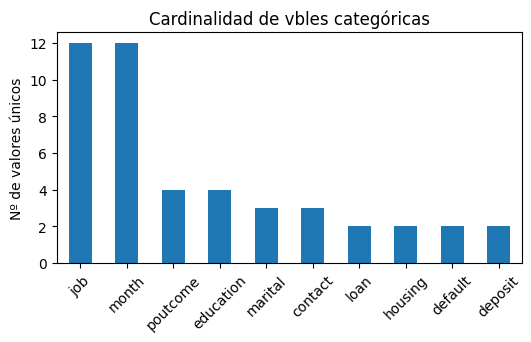

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
cardinality.plot(kind="bar")
plt.title("Cardinalidad de vbles categóricas")
plt.ylabel("Nº de valores únicos")
plt.xticks(rotation=45)
plt.show()

Observamos que hay dos variables con alta cardinalidad (más de 10 valores únicos): `job` y `month` con 12 categorías.

Estas variables se tratarán en el preprocesamiento usando variables dummy.

## 2.4 Valores faltantes

In [42]:
print("How many missing values per attribute:")
print("======================================")
print(df.isnull().sum())

How many missing values per attribute:
age            0
job            0
marital      406
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
deposit        0
dtype: int64


In [44]:
missing_values = df.isnull().sum()
print("\nVariables con missing values:")
print(missing_values[missing_values > 0])


Variables con missing values:
marital    406
dtype: int64


Solo tiene valores ausentes la variable `marital`, con un total de 406, que se tratarán en el preprocesamiento usando la técnica de X

## 2.5 Columnas constantes o tipo ID

In [ ]:
for col in df.columns:
    if df[col].nunique() == 1:
        print(col)

No se observan columnas constantes ni columnas que actúen como identificadores únicos.

## 2.6 Análisis de la variable objetivo

In [ ]:
df['deposit'].value_counts()

deposit
no     5780
yes    5220
Name: count, dtype: int64

In [ ]:
df['deposit'].value_counts(normalize=True)

deposit
no     0.525455
yes    0.474545
Name: proportion, dtype: float64

La variable `deposit` indica si el cliente suscribió un depósito.

Se trata de un problema de clasificación binaria, con dos clases: "yes" y "no".

La distribución de clases es:

- 52.55% para la clase "no"
- 47.45% para la clase "yes"

Por tanto, el dataset está ligeramente desbalanceado, aunque la diferencia entre clases no es significativa. No se observa un desbalanceo severo.

## 2.7 Análisis de la variable `pdays`

In [ ]:
df['pdays'].value_counts()

pdays
-1      8203
 92      105
 182      88
 91       82
 181      79
        ... 
 651       1
 214       1
 24        1
 701       1
 118       1
Name: count, Length: 472, dtype: int64

In [ ]:
(df['pdays'] == -1).mean()

np.float64(0.7457272727272727)

La variable `pdays` representa el número de días transcurridos desde el último contacto en una campaña anterior.

Se observa que el valor -1 aparece 8203 veces, lo que representa aproximadamente el 74.57% del dataset.

Este valor no representa un número real de días, sino una codificación especial que indica ausencia de contacto previo.

Esto indica que una gran parte de los clientes no fueron contactados previamente.

Por tanto, el valor -1 no debe interpretarse como un valor numérico válido, y será necesario tratarlo adecuadamente durante el preprocesamiento.

Una estrategia razonable sería:

- Convertir el valor -1 en un valor nulo (NaN) y posteriormente imputarlo.
- O crear una variable binaria adicional que indique si el cliente fue contactado previamente, manteniendo `pdays` solo para los casos válidos.

Este tratamiento es importante, ya que dejar el valor -1 como un número puede inducir errores en los modelos.

## 2.8 Conclusiones del EDA

El dataset contiene variables numéricas y categóricas, con valores faltantes únicamente en la variable `marital` (406 valores), que deberán imputarse durante el preprocesamiento.

Existen variables categóricas con alta cardinalidad (`job` y `month`), que requerirán una codificación adecuada, como One-Hot Encoding.

El problema es de clasificación binaria y el conjunto presenta un ligero desbalanceo entre clases (aproximadamente 52.55% frente a 47.45%), aunque no se trata de un desbalanceo severo.

La variable `pdays` requiere un tratamiento especial debido a la presencia masiva del valor -1 (74.57% del dataset), que representa ausencia de contacto previo.

# 3. Decidir cómo se va a realizar la evaluación

En esta sección se define la estrategia de evaluación del modelo, incluyendo la partición de los datos, la métrica seleccionada y el procedimiento de validación que se utilizará para estimar el rendimiento del modelo.

## 3.1 Estrategia de partición de datos

## 3.2 Métricas de evaluación

## 3.3 Validación del modelo

## 3.4 Reproducibilidad